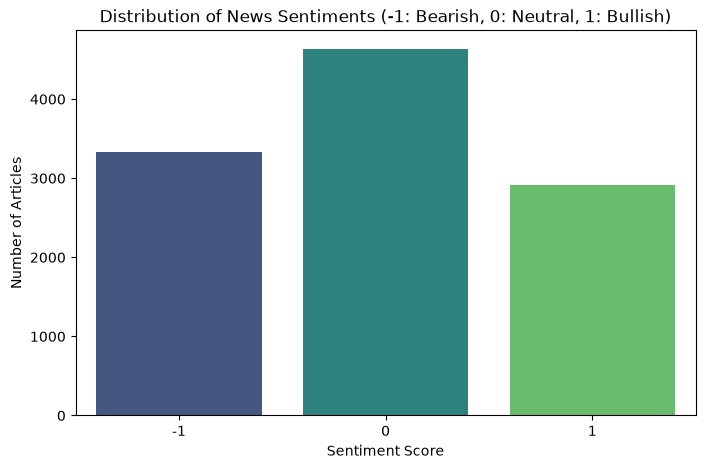

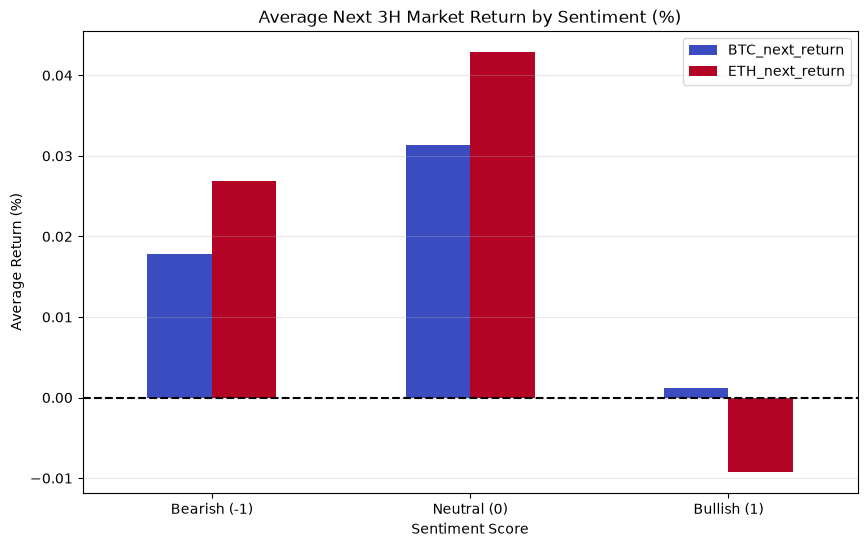

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1. Load processed news data
processed_path = r"E:\Innovus\Documents\Agentic-AI-Based-Market-Intelligence-Framework-For-Bitcoin-and-Ethereum-Trading\Vibhu Kalpitha\data\02_processed\news_cleaned_3h.csv"
df = pd.read_csv(processed_path)
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# 2. News Sentiment Distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='sentiment_score', data=df, palette='viridis')
plt.title("Distribution of News Sentiments (-1: Bearish, 0: Neutral, 1: Bullish)")
plt.xlabel("Sentiment Score")
plt.ylabel("Number of Articles")
plt.show()

# 3. Market Reaction to News (Average Returns)
# ඊළඟ පැය 3 ඇතුළත Price එක වෙනස් වෙන ප්‍රතිශතය හදමු
df['BTC_next_return'] = (df['BTC_close'].shift(-1) / df['BTC_close'] - 1) * 100
df['ETH_next_return'] = (df['ETH_close'].shift(-1) / df['ETH_close'] - 1) * 100

avg_returns = df.groupby('sentiment_score')[['BTC_next_return', 'ETH_next_return']].mean()

plt.figure(figsize=(10, 6))
avg_returns.plot(kind='bar', colormap='coolwarm', ax=plt.gca())
plt.title("Average Next 3H Market Return by Sentiment (%)")
plt.xlabel("Sentiment Score")
plt.ylabel("Average Return (%)")
plt.axhline(0, color='black', linewidth=1.5, linestyle='--')
plt.xticks(ticks=[0, 1, 2], labels=['Bearish (-1)', 'Neutral (0)', 'Bullish (1)'], rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()